# 18 The sample: precursor E_peak in merger candidates and in collapsars

The aim of the project is to find out if a precursor can pick out merger-origin long GRBs without a kilonova. So far the pipeline has only seen the two bursts we already knew about. This notebook runs it on others, which is Objective 5 of the proposal.

Zhu et al. (2026, arXiv 2604.19182) separate mergers from collapsars in 366 GBM bursts using the precursor's duration and MVT, the quiet gap and the main emission's E_peak, but not the precursor's own E_peak. Tan et al. (2025, arXiv 2504.06616) find five long merger candidates and fit their precursors. So the question here is: does the precursor's E_peak tell the two classes apart?

- Merger candidates (Tan et al.; Zhu et al.): GRB 170228A, GRB 200311A, GRB 200914A. None has a confirmed kilonova.
- Collapsars with a supernova and a precursor (Zhu et al.'s six): GRB 180728A, GRB 190829A, GRB 190114C, GRB 090618, GRB 111228A, GRB 211023A. The supernovae of the last two rest on photometry only, so those two labels are the weakest.
- For comparison, the two with a kilonova, from notebooks 12 and 14.

This direction is proposed and not yet agreed with my supervisor. Every burst is set up the same way from the catalogue's detectors and T90 (`sample_tools.py`), with no tuning by hand. No MVT is computed here; section 6 only asks how much signal each precursor has.

In [1]:
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.cosmology import Planck18, z_at_value
from scipy.stats import rankdata

from gdt.core.spectra.functions import Comptonized
from gdt.missions.fermi.gbm.tte import GbmTte

from settings import CODE_DIR, FIGURE_DIR, WINDOWS_FILE
from lightcurve_tools import aligned_bin_edges, background_in_band, fit_background, tte_path
from spectral_fit_tools import cstat, covariance, fit_model, make_spectra, scaled_starts, window_response
from sample_tools import (background_windows, blocks_of, burst_info, fit_episode, main_stop, net_light_curve, precursor_from_blocks)

warnings.filterwarnings("ignore")     # GDT's fitter warns on most trial steps near the parameter limits
pd.set_option("display.width", 220)
SHARED = WINDOWS_FILE.parent
DATA_ROOT = CODE_DIR.parent / "data" / "fermiGBM"
ALL_NAI = [f"n{i}" for i in range(10)] + ["na", "nb"]

SAMPLE = pd.DataFrame([
    ("GRB170228A", "bn170228794", "candidate", np.nan, 0.032),
    ("GRB200311A", "bn200311636", "candidate", np.nan, 0.016),
    ("GRB200914A", "bn200914534", "candidate", np.nan, 0.016),
    ("GRB180728A", "bn180728728", "collapsar", 0.117, 0.016),
    ("GRB190829A", "bn190829830", "collapsar", 0.0785, 0.032),
    ("GRB190114C", "bn190114873", "collapsar", 0.4245, 0.016),
    ("GRB090618", "bn090618353", "collapsar", 0.54, 0.032),
    ("GRB111228A", "bn111228657", "collapsar", 0.716, 0.032),
    ("GRB211023A", "bn211023546", "collapsar", 0.390, 0.032),
], columns=["burst", "trigger", "group", "z", "bin_s"]).set_index("burst")
info = {b: burst_info(DATA_ROOT / b / "current", r.trigger) for b, r in SAMPLE.iterrows()}
for b, i in list(info.items()):
    if i["t90_start"] - 5.0 <= i["tte_range"][0] + 1.0:
        print(f"{b}: left out. T90 starts at {i['t90_start']:.1f} s and the TTE only at {i['tte_range'][0]:.1f} s, so there's no background before the burst and its first emission isn't in the data")
        SAMPLE, _ = SAMPLE.drop(b), info.pop(b)
pd.DataFrame({b: dict(T90=i["t90"], T90_start=i["t90_start"], detectors=" ".join(i["detectors"]), angles=" ".join(f"{i['angles'][d]:.0f}" for d in i["detectors"]),
                      catalogue_interval=f"{i['catalogue']['interval'][0]:g} to {i['catalogue']['interval'][1]:g}", catalogue_Ep=i["catalogue"]["Ep"], catalogue_alpha=i["catalogue"]["alpha"]) for b, i in info.items()}).T.round(2)

GRB111228A: left out. T90 starts at -49.4 s and the TTE only at -33.7 s, so there's no background before the burst and its first emission isn't in the data


,T90,T90_start,detectors,angles,catalogue_interval,catalogue_Ep,catalogue_alpha
GRB170228A,60.673,1.568,b1 n2 n9 na,91 38 44 40,0 to 90.112,751.578308,-0.80108
GRB200311A,52.4809,1.05599,n8 n4 b1,33 59 72,-1.024 to 66.56,1351.75708,-1.01561
GRB200914A,65.2811,1.56799,n3 n5 n4 b0,28 34 49 32,-1.024 to 81.92,2010.503052,-1.191053
GRB180728A,6.4001,10.2401,n6 n7 n3 b1,21 28 33 87,-6.144 to 31.744,85.509697,-1.643693
GRB190829A,59.3931,0.51197,n6 n7 n9 b1,12 14 50 65,-1.024 to 68.608,8.541841,-1.9
GRB190114C,116.354,0.703988,n4 n3 n8 b0,37 41 42 87,-5.12 to 236.544,1574.370361,-1.233157
GRB090618,112.386,7.93609,b0 n4,69 42,-1.024 to 174.08,209.931442,-1.253824
GRB211023A,79.1055,55.041,n7 n6 n8 b1,28 40 40 81,-76.8 to 178.176,100.160278,-1.752008


## 1. Finding the precursor

One rule for every burst, from Bayesian blocks on the NaI light curve at 8-1000 keV. A block is quiet if it is below 5 sigma and below a quarter of the highest excess so far. The gap is the first run of quiet blocks before the burst's highest block, unless a later run is more than twice as long. The precursor is everything significant before the gap. The main emission starts after the gap and ends at the first block at least 0.5 s long below 10% of its peak.

The rule is mine, written after looking at these light curves, so agreement with the published durations is a check on it and not independent evidence. For the three candidates Tan et al.'s Table 1 gives the precursor and gap durations, and for the collapsars I compare by eye with the shaded windows in Zhu et al.'s Fig. A1. The background before the burst ends 5 s before the first significant block, so it needs a first pass to find that block.

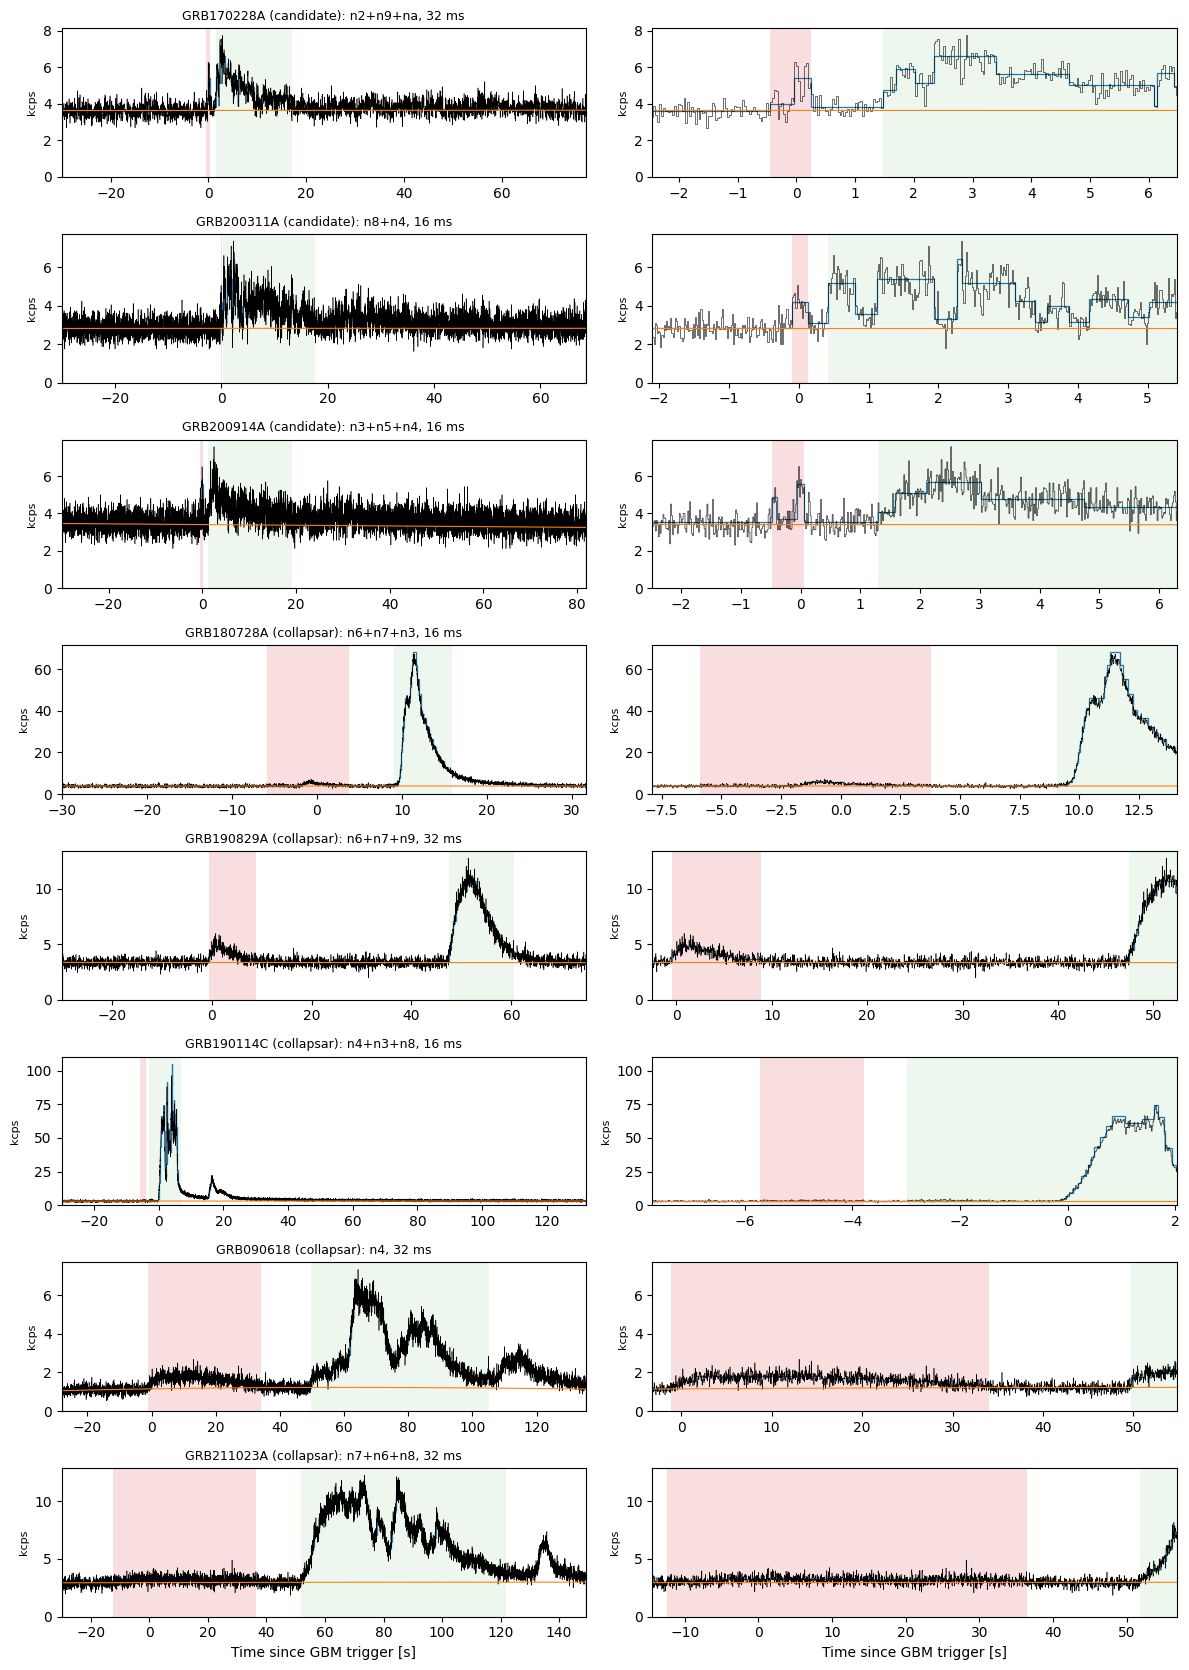

,pre_start,pre_stop,T_pre,T_pre_published,gap,gap_published,main_start,main_stop,gap_sigma,pre_peak_over_main_peak
burst,,,,,,,,,,
GRB170228A,-0.448,0.256,0.704,0.8,1.216,1.2,1.472,17.024,3.981,0.599
GRB200311A,-0.096,0.128,0.224,0.4,0.288,0.2,0.416,17.552,2.239,0.372
GRB200914A,-0.480,0.064,0.544,0.4,1.232,1.2,1.296,19.168,0.773,0.929
GRB180728A,-5.888,3.808,9.696,NaN,5.280,NaN,9.088,15.952,1.441,0.027
GRB190829A,-0.512,8.864,9.376,NaN,38.592,NaN,47.456,60.512,4.234,0.203
GRB190114C,-5.712,-3.776,1.936,NaN,0.800,NaN,-2.976,6.800,-1.645,0.003
GRB090618,-1.184,34.080,35.264,NaN,15.712,NaN,49.792,105.184,0.662,0.130
GRB211023A,-12.384,36.416,48.800,NaN,15.392,NaN,51.808,121.856,0.550,0.042


In [2]:
PUBLISHED = {"GRB170228A": (0.80, 1.20), "GRB200311A": (0.40, 0.20), "GRB200914A": (0.40, 1.20)}
blocks, windows, curves = {}, {}, {}
for burst, r in SAMPLE.iterrows():
    i = info[burst]
    data_dir = DATA_ROOT / burst / "current"
    nai = [d for d in i["detectors"] if d.startswith("n")]
    span = (max(i["tte_range"][0] + 1.0, -30.0), i["t90_start"] + i["t90"] + 15.0)
    edges = np.round(aligned_bin_edges(span, r.bin_s), 6)
    c, x, b = net_light_curve(data_dir, r.trigger, nai, (8.0, 1000.0), edges, background_windows(i))
    blocks[burst] = blocks_of(c, x, b, edges)
    # the pre-burst background has to stop before the burst does anything, which can be well before T0
    first_block = blocks[burst].start[int(np.argmax(blocks[burst].sigma.values > 3.0))]
    pre_stop = max(min(background_windows(i)[0][1], first_block - 5.0), i["tte_range"][0] + 6.0)
    if pre_stop < background_windows(i)[0][1] - 0.5:
        i["bkg_pre_stop"] = pre_stop
        c, x, b = net_light_curve(data_dir, r.trigger, nai, (8.0, 1000.0), edges, background_windows(i))
        blocks[burst] = blocks_of(c, x, b, edges)
    curves[burst] = (edges, c, b, nai)
    found = precursor_from_blocks(blocks[burst])
    windows[burst] = None if found is None else dict(found, main_stop=main_stop(blocks[burst], found["main_start"]))
rows = []
for burst, w in windows.items():
    if w is None:
        rows.append(dict(burst=burst, note="no separate precursor by this rule"))
        continue
    t_pre, t_gap = PUBLISHED.get(burst, (np.nan, np.nan))
    rows.append(dict(burst=burst, pre_start=w["pre_start"], pre_stop=w["pre_stop"], T_pre=w["pre_stop"] - w["pre_start"], T_pre_published=t_pre, gap=w["main_start"] - w["pre_stop"], gap_published=t_gap,
                     main_start=w["main_start"], main_stop=w["main_stop"], gap_sigma=w["gap_sigma"], pre_peak_over_main_peak=w["pre_peak"] / w["main_peak"]))
window_table = pd.DataFrame(rows).set_index("burst")

fig, axes = plt.subplots(len(SAMPLE), 2, figsize=(12, 2.1 * len(SAMPLE)), squeeze=False)
for row, (burst, r) in zip(axes, SAMPLE.iterrows()):
    edges, c, b, nai = curves[burst]
    centres = 0.5 * (edges[1:] + edges[:-1])
    w = windows[burst]
    start = w["pre_start"] if w else blocks[burst].start[int(np.argmax(blocks[burst].sigma.values > 3.0))]
    end = (w["main_start"] + 5.0) if w else start + 15.0
    for ax, xr in ((row[0], (edges[0], edges[-1])), (row[1], (start - 2.0, end))):
        ax.step(centres, c / np.diff(edges) / 1e3, where="mid", color="k", lw=0.4)
        ax.plot(centres, b / np.diff(edges) / 1e3, color="tab:orange", lw=0.8)
        ax.stairs(blocks[burst].rate.values / 1e3, np.append(blocks[burst].start.values, blocks[burst].stop.values[-1]), color="tab:blue", lw=0.9)
        if w:
            ax.axvspan(w["pre_start"], w["pre_stop"], color="tab:red", alpha=0.15, lw=0)
            ax.axvspan(w["main_start"], w["main_stop"], color="tab:green", alpha=0.08, lw=0)
        ax.set_xlim(*xr)
        ax.set_ylabel("kcps", fontsize=8)
    row[0].set_title(f"{burst} ({r.group}): {'+'.join(nai)}, {1e3 * r.bin_s:.0f} ms", fontsize=9)
axes[-1, 0].set_xlabel("Time since GBM trigger [s]")
axes[-1, 1].set_xlabel("Time since GBM trigger [s]")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "18_sample_lightcurves.png", dpi=150)
plt.show()
window_table.round(3)

The rule finds sensible windows in all eight. For the three candidates the precursors come out at 0.70, 0.22 and 0.54 s against Tan et al.'s 0.8, 0.4 and 0.4 s, and the gaps at 1.22, 0.29 and 1.23 s against 1.2, 0.2 and 1.2 s. For the collapsars they match the shaded windows in Zhu et al.'s Fig. A1 by eye: about -6 to 4 s for 180728A, -1 to 9 s for 190829A, 0 to 38 s for 090618 and -14 to 38 s for 211023A.

GRB 190114C is the odd one. The rule finds -5.71 to -3.78 s, where Zhu et al. shade about -5 to -2.2 s. It is a very faint excess before a very bright burst, and section 3 shows it isn't significant. The rule also starts the main emission at -2.98 s, when the rate only really rises at about -0.1 s, but what comes before is so faint that it makes no difference to the spectrum.

GRB 111228A is left out, for the reason printed at the top. Swift triggered on it 47.8 s before GBM did, so its first emission isn't in the TTE, and neither is any background before it.

## 2. Check against the GBM catalogue

The same check as for the two known bursts: the catalogue's detectors, channels and interval, a Comptonized fit with my background, compared with the catalogue's fluence fit. If this works the data handling is right for each burst, before any precursor result is read.

In [3]:
rows = []
for burst, r in SAMPLE.iterrows():
    i = info[burst]
    data_dir = DATA_ROOT / burst / "current"
    interval = i["catalogue"]["interval"]
    spectra = {d: make_spectra(data_dir, r.trigger, d, {"cat": interval}, background_windows(i), 3)[0]["cat"] for d in i["detectors"]}
    rsps = [window_response(data_dir, r.trigger, d, interval)[0] for d in i["detectors"]]
    masks = [(np.arange(128) >= i["channels"][d][0]) & (np.arange(128) <= i["channels"][d][-1]) for d in i["detectors"]]
    data = ([spectra[d][0] for d in i["detectors"]], [spectra[d][1] for d in i["detectors"]], rsps, masks)
    model = Comptonized()
    fit = fit_model(*data, model, scaled_starts(model, *data, [[1.0, e, a, 100.0] for e in (100.0, 400.0, 1500.0) for a in (-0.7, -1.3)]), polish=True)
    with np.errstate(invalid="ignore"):
        err = np.sqrt(np.diag(covariance(fit)))
    rows.append(dict(burst=burst, interval=f"{interval[0]:g} to {interval[1]:g}", Ep=fit.parameters[1], Ep_err=err[1], Ep_catalogue=i["catalogue"]["Ep"], Ep_catalogue_err=i["catalogue"]["Ep_err"], alpha=fit.parameters[2], alpha_catalogue=i["catalogue"]["alpha"]))
catalogue_check = pd.DataFrame(rows).set_index("burst")
catalogue_check["Ep_ratio"] = catalogue_check.Ep / catalogue_check.Ep_catalogue
catalogue_check.round(3)

,interval,Ep,Ep_err,Ep_catalogue,Ep_catalogue_err,alpha,alpha_catalogue,Ep_ratio
burst,,,,,,,,
GRB170228A,0 to 90.112,1044.294,160.241,751.578,64.544,-0.974,-0.801,1.389
GRB200311A,-1.024 to 66.56,1166.417,92.686,1351.757,83.926,-0.953,-1.016,0.863
GRB200914A,-1.024 to 81.92,5286.390,1613.320,2010.503,336.953,-1.489,-1.191,2.629
GRB180728A,-6.144 to 31.744,85.319,1.429,85.510,1.565,-1.621,-1.644,0.998
GRB190829A,-1.024 to 68.608,8.413,1.694,8.542,0.245,-1.896,-1.900,0.985
GRB190114C,-5.12 to 236.544,1650.705,53.257,1574.370,45.068,-1.219,-1.233,1.048
GRB090618,-1.024 to 174.08,247.581,4.198,209.931,3.297,-1.189,-1.254,1.179
GRB211023A,-76.8 to 178.176,112.277,3.608,100.160,2.742,-1.736,-1.752,1.121


180728A, 190829A and 190114C come back within 5%, and 170228A and 200311A within 2 sigma. The two long, structured bursts are further off with small errors: 211023A is 12% high (2.7 sigma) and 090618 18% high (7 sigma). These are averages over 175-255 s while the spectrum changes, and the catalogue's background comes from a longer stretch of data than the TTE covers. I can't say which is closer, and I treat it as a 10-20% uncertainty, the same scale as GBM against GECAM in notebook 15.

200914A is the worst: 5286 +/- 1613 keV against 2010 +/- 337 keV (2 sigma), with alpha -1.49 against -1.19. Its catalogue window is 83 s of a faint burst, so the background decides the answer: C/dof is about 3.6, and with my usual channels E_p runs from about 4300 to 6400 keV for background orders 1 to 3. In 0.3-19 s, the part that matters here, it is stable at 1630-1680 keV with C/dof 1.5. So this check doesn't tell us much for this burst, and its main emission gets another comparison in section 4.

## 3. The fits

For each burst, the precursor and the main emission: power law, Comptonized, Band and blackbody. I use the Comptonized E_p throughout, since Band's tail usually isn't measurable in a faint precursor, and one model makes the bursts comparable. A precursor counts as measured if the Comptonized fit beats the power law by Delta C > 9 (3 sigma for one extra parameter); otherwise E_p isn't constrained by these data. It counts as usable at all if its net counts are at least 5 sigma above the background (net over the square root of the total, summed over the detectors). Errors are from the profile likelihood, with the 95% range next to them.

For GRB 190114C, Zhu et al.'s figure shades about -5 to -2.2 s, which is wider than what my rule finds, so I fit that window too.

In [4]:
results = []
for burst, r in SAMPLE.iterrows():
    w = windows[burst]
    if w is None:
        continue
    i = info[burst]
    data_dir = DATA_ROOT / burst / "current"
    episode_windows = {"pre": (w["pre_start"], w["pre_stop"]), "main": (w["main_start"], w["main_stop"])}
    spectra = {d: make_spectra(data_dir, r.trigger, d, episode_windows, background_windows(i), 3)[0] for d in i["detectors"]}
    for label, window in episode_windows.items():
        results.append(dict(burst=burst, group=r.group, episode=label, **fit_episode(data_dir, r.trigger, i["detectors"], spectra, label, window)))
fits_table = pd.DataFrame(results)

window = (-5.0, -2.2)
i = info["GRB190114C"]
data_dir = DATA_ROOT / "GRB190114C" / "current"
spectra = {d: make_spectra(data_dir, SAMPLE.trigger["GRB190114C"], d, {"pre_zhu": window}, background_windows(i), 3)[0] for d in i["detectors"]}
extra = dict(burst="GRB190114C", group="collapsar", episode="pre_zhu", **fit_episode(data_dir, SAMPLE.trigger["GRB190114C"], i["detectors"], spectra, "pre_zhu", window))
fits_table = pd.concat([fits_table, pd.DataFrame([extra])], ignore_index=True)

fits_table["dC_pl_minus_cpl"] = fits_table.C_pl - fits_table.C_cpl
fits_table["dC_bb_minus_cpl"] = fits_table.C_bb - fits_table.C_cpl
fits_table["dC_cpl_minus_band"] = fits_table.C_cpl - fits_table.C_band
fits_table["sigma"] = fits_table.net_counts / np.sqrt(fits_table.gross_counts)
fits_table["usable"] = fits_table.sigma >= 5.0
fits_table["measured"] = fits_table.usable & (fits_table.dC_pl_minus_cpl > 9.0)
fits_table.to_csv(SHARED / "sample_fits.csv", index=False, float_format="%.5g")
fits_table[["burst", "episode", "t_start", "t_stop", "net_counts", "sigma", "Ep", "Ep_err_lo", "Ep_err_hi", "Ep_limit_lo", "Ep_limit_hi", "alpha", "alpha_err", "pl_index", "dC_pl_minus_cpl", "dC_bb_minus_cpl", "dC_cpl_minus_band", "Ep_band", "beta_band", "kT", "usable", "measured"]].round(2)

,burst,episode,t_start,t_stop,net_counts,sigma,Ep,Ep_err_lo,Ep_err_hi,Ep_limit_lo,...,alpha_err,pl_index,dC_pl_minus_cpl,dC_bb_minus_cpl,dC_cpl_minus_band,Ep_band,beta_band,kT,usable,measured
0,GRB170228A,pre,-0.45,0.26,825.88,12.04,531.64,131.18,252.08,344.87,...,0.24,-1.36,56.95,16.87,0.19,493.73,-2.88,69.44,True,True
1,GRB170228A,main,1.47,17.02,22938.82,69.60,762.26,47.99,53.79,686.09,...,0.04,-1.34,1548.39,606.10,-0.00,762.40,-10.00,85.15,True,True
2,GRB200311A,pre,-0.10,0.13,341.41,8.54,239.13,53.58,100.13,162.13,...,0.27,-1.53,16.33,18.65,1.48,132.99,-2.00,34.44,True,True
3,GRB200311A,main,0.42,17.55,33781.82,93.78,1174.71,59.20,63.14,1079.73,...,0.03,-1.36,2592.80,1543.57,0.42,1170.78,-4.31,144.05,True,True
4,GRB200914A,pre,-0.48,0.06,594.40,9.69,1260.18,629.36,1146.60,441.81,...,0.17,-1.41,19.62,16.16,-0.00,1260.12,-10.00,62.51,True,True
5,GRB200914A,main,1.30,19.17,22499.53,63.31,1666.02,169.64,184.90,1395.68,...,0.03,-1.36,679.47,961.78,0.00,1648.92,-4.22,79.29,True,True
6,GRB180728A,pre,-5.89,3.81,5709.56,22.60,13.37,2.41,4.09,9.71,...,0.07,-2.24,-2.09,156.04,4.60,14.51,-2.31,5.99,True,False
7,GRB180728A,main,9.09,15.95,181102.32,384.67,101.22,1.20,1.20,99.24,...,0.01,-1.92,3481.41,56342.04,43.24,91.70,-2.66,13.76,True,True
8,GRB190829A,pre,-0.51,8.86,8447.71,33.18,116.15,17.88,29.30,89.74,...,0.07,-1.82,15.26,407.61,2.32,68.87,-2.06,11.06,True,True
9,GRB190829A,main,47.46,60.51,56771.06,154.61,6.98,0.76,0.04,6.18,...,0.02,-2.46,-408.67,6162.53,474.24,10.25,-2.52,4.92,True,False


Seven of the eight precursors are usable. GRB 190114C's isn't: 3.6 sigma in my window and 3.7 sigma in Zhu et al.'s, so it stays in the table and out of the comparison.

Six have a measured E_p: 532 (-131/+252) keV for 170228A, 239 (-54/+100) for 200311A, 1260 (-629/+1147) for 200914A, 116 (-18/+29) for 190829A, 256 (-9/+10) for 090618 and 91 (-9/+11) for 211023A. 180728A's isn't measured: its power-law index is -2.24, so nuFnu falls across the whole band and the Comptonized fit doesn't improve on the power law. That means a soft precursor with E_p at or below the bottom of the band, with a 95% limit of 22 keV.

So the candidates' precursors are hard, at or above 239 keV with large errors, and all harder than the two kilonova bursts' (67 and 199 keV). A blackbody is worse than a Comptonized in every usable precursor, by 16-19 in the candidates, though it has one parameter fewer.

The main emission needs more care. Band isn't needed for the candidates, but it is for every collapsar (Delta C 31-474). In 190829A the Comptonized E_p of 7 keV sits at the bottom of the band and a power law actually does better, so that number isn't usable. Band gives 10.2 keV with beta -2.52. That's why the ratio in section 7 is also worked out with the best model.

## 4. Against Tan et al.'s fits, in their windows

Their Table 2 gives alpha and E_cut for a Comptonized model, so E_p = (2 + alpha) E_cut, and a blackbody kT. I fit their windows with my pipeline and detectors.

In [5]:
TAN = {"GRB170228A": dict(pre=(-0.5, 0.3, -1.05, 1160.0, 57.10), main=(1.4, 20.0, -0.64, 606.0, np.nan)),
       "GRB200311A": dict(pre=(-0.3, 0.1, -1.46, 2340.0, 25.50), main=(0.3, 18.0, -0.66, 856.0, np.nan)),
       "GRB200914A": dict(pre=(-0.3, 0.1, -0.74, 835.0, 69.9), main=(0.3, 19.0, -0.78, 930.0, np.nan))}
rows = []
for burst, table in TAN.items():
    i = info[burst]
    data_dir = DATA_ROOT / burst / "current"
    tan_windows = {k: v[:2] for k, v in table.items()}
    spectra = {d: make_spectra(data_dir, SAMPLE.trigger[burst], d, tan_windows, background_windows(i), 3)[0] for d in i["detectors"]}
    for label, (t0, t1, alpha, ecut, kt) in table.items():
        f = fit_episode(data_dir, SAMPLE.trigger[burst], i["detectors"], spectra, label, (t0, t1))
        rows.append(dict(burst=burst, episode=label, window=f"{t0:g} to {t1:g}", Ep_mine=f["Ep"], Ep_lo=f["Ep_err_lo"], Ep_hi=f["Ep_err_hi"], Ep_tan=(2 + alpha) * ecut, alpha_mine=f["alpha"], alpha_err=f["alpha_err"], alpha_tan=alpha, kT_mine=f["kT"], kT_tan=kt, dC_bb_minus_cpl=f["C_bb"] - f["C_cpl"]))
tan_check = pd.DataFrame(rows).set_index(["burst", "episode"])
tan_check.round(2)

window  Ep_mine   Ep_lo   Ep_hi   Ep_tan  alpha_mine  alpha_err  alpha_tan  kT_mine  kT_tan  dC_bb_minus_cpl
burst      episode                                                                                                                   
GRB170228A pre      -0.5 to 0.3   506.31  118.64  222.32  1102.00       -0.42       0.25      -1.05    70.80    57.1            16.45
           main       1.4 to 20   766.50   50.39   56.75   824.16       -0.55       0.04      -0.64    83.83     NaN           567.03
GRB200311A pre      -0.3 to 0.1   380.43  166.29  499.49  1263.60       -1.18       0.22      -1.46    29.18    25.5            16.08
           main       0.3 to 18  1174.31   59.18   63.59  1147.04       -0.67       0.03      -0.66   142.72     NaN          1515.79
GRB200914A pre      -0.3 to 0.1   658.64  230.94  737.36  1052.10       -0.54       0.31      -0.74    73.35    69.9             6.85
           main       0.3 to 19  1627.27  166.99  184.06  1134.60       -0.93       0.03      -0.78   139.22     NaN          1236.95

For the main emission 767 keV against their 824 keV and 1174 keV against 1147 keV agree. 200914A is about 2 sigma off, 1627 (-167/+184) keV against 1135 (+146/-129) keV. With n3 and b0 alone I get 1443 +/- 168 keV, and the background order moves it by about 50 keV, so neither explains it, and I leave it open.

For the precursors their errors are as big as the values. Scaling their E_cut errors to E_p gives ranges of about 490-2780, 470-2160 and 360-3100 keV, and mine (506, 380 and 659 keV) fall inside or close to them. So the precursors do look hard, but not necessarily as hard as their central values. kT comes out at 70.8, 29.2 and 73.4 keV against their 57.1, 25.5 and 69.9 keV. For 200914A the blackbody is worse by only 7, and with one parameter fewer the two are about level, as they find.

## 5. Rates

The rule of thumb from notebook 15: E_peak moves by about 1% per 12 kcps in the BGO. So the highest recorded rate in 16 ms bins in each episode says if pile-up needs thinking about, and the summed rate of the catalogue's detectors is only a guide, since the telemetry limit is on all 14.

In [6]:
rows = []
for burst, r in SAMPLE.iterrows():
    w = windows[burst]
    if w is None:
        continue
    data_dir = DATA_ROOT / burst / "current"
    row = dict(burst=burst)
    for label, window in (("pre", (w["pre_start"], w["pre_stop"])), ("main", (w["main_start"], w["main_stop"]))):
        edges = aligned_bin_edges(window, 0.016)
        peak = {}
        for det in info[burst]["detectors"]:
            tte = GbmTte.open(tte_path(data_dir, r.trigger, det))
            peak[det] = (np.histogram(np.asarray(tte.data.times), bins=edges)[0] / np.diff(edges)).max() / 1e3
            tte.close()
        row[f"{label}_bgo_max_kcps"] = max(v for d, v in peak.items() if d.startswith("b"))
        row[f"{label}_nai_max_kcps"] = max(v for d, v in peak.items() if d.startswith("n"))
    rows.append(row)
rate_table = pd.DataFrame(rows).set_index("burst")
rate_table["main_bias_estimate_pct"] = rate_table.main_bgo_max_kcps / 12.0
rate_table.round(1)

,pre_bgo_max_kcps,pre_nai_max_kcps,main_bgo_max_kcps,main_nai_max_kcps,main_bias_estimate_pct
burst,,,,,
GRB170228A,3.6,2.9,3.9,3.7,0.3
GRB200311A,3.8,3.0,6.4,4.2,0.5
GRB200914A,3.6,2.4,4.6,3.2,0.4
GRB180728A,3.5,3.1,6.7,26.6,0.6
GRB190829A,4.2,3.0,4.0,5.7,0.3
GRB190114C,4.5,2.1,36.3,32.9,3.0
GRB090618,3.7,3.0,6.8,7.9,0.6
GRB211023A,2.7,2.2,3.3,5.4,0.3


None of the precursors is anywhere near trouble: 4.5 kcps at most, close to background. The only main emission with enough rate to matter is 190114C's (36 kcps in the BGO, about 3% by the rule of thumb), and 180728A reaches 27 kcps in the NaI. So pile-up isn't an issue for anything used here.

## 6. Is there enough signal for an MVT?

Rodrigo's trust curve says that in precursor-like conditions the MVT can be trusted from an SNR_MVT of about 35-80. This is his definition, as in notebook 17: the highest count in bins of width tau over the square root of the background in such a bin, 8-900 keV, first-order background, with Bala et al.'s detector rule. I work it out for each precursor at a range of timescales, as a first estimate of which ones are worth a run on Chandra. The background intervals here are mine, not his.

The definition uses the total count, background included, so the background alone already gives a value of about the square root of its counts per bin, plus the largest fluctuation. So next to each precursor I work out the same thing in a quiet stretch of the same length before the burst.

In [7]:
TAUS = (4e-3, 8e-3, 16e-3, 32e-3, 64e-3)

def best_snr(events, rates, window, tau):
    edges = np.arange(window[0], window[1] + tau, tau)
    hist = {d: np.histogram(events[d], bins=edges)[0] for d in ALL_NAI}
    snr_of = lambda ds: sum(hist[d] for d in ds).max() / np.sqrt(sum(rates[d] for d in ds) * tau)
    ranked = sorted(ALL_NAI, key=lambda d: snr_of([d]), reverse=True)
    return max(snr_of(ranked[:k]) for k in range(1, 13))

def rate_in(fitter, window):
    return float(np.sum(background_in_band(fitter, (8.0, 900.0), np.linspace(window[0], window[1], 3))[0])) / (window[1] - window[0])

rows = []
for burst, r in SAMPLE.iterrows():
    w = windows[burst]
    if w is None:
        continue
    i = info[burst]
    data_dir = DATA_ROOT / burst / "current"
    window = (w["pre_start"], w["pre_stop"])
    # a stretch of the same length before the burst, or as much as the TTE has
    quiet_stop = background_windows(i)[0][1]
    quiet = (max(quiet_stop - (window[1] - window[0]), i["tte_range"][0] + 1.0), quiet_stop)
    events, rates, rates_quiet = {}, {}, {}
    for det in ALL_NAI:
        tte = GbmTte.open(tte_path(data_dir, r.trigger, det))
        events[det] = np.sort(np.asarray(tte.slice_energy((8.0, 900.0)).data.times))
        tte.close()
        fitter = fit_background(data_dir, r.trigger, det, background_windows(i), 1)[0]
        rates[det], rates_quiet[det] = rate_in(fitter, window), rate_in(fitter, quiet)
    row = dict(burst=burst, group=r.group, T_pre=window[1] - window[0])
    for tau in TAUS:
        too_long = tau > 0.25 * (window[1] - window[0])
        row[f"snr_{1e3 * tau:.0f}ms"] = np.nan if too_long else best_snr(events, rates, window, tau)
        row[f"quiet_{1e3 * tau:.0f}ms"] = np.nan if too_long else best_snr(events, rates_quiet, quiet, tau)
    rows.append(row)
snr_table = pd.DataFrame(rows).set_index("burst")
snr_table.to_csv(SHARED / "sample_snr.csv", float_format="%.4g")
snr_table.round(1)

,group,T_pre,snr_4ms,quiet_4ms,snr_8ms,quiet_8ms,snr_16ms,quiet_16ms,snr_32ms,quiet_32ms,snr_64ms,quiet_64ms
burst,,,,,,,,,,,,
GRB170228A,candidate,0.7,13.8,9.7,18.2,11.7,24.3,16.0,30.4,21.0,42.2,28.3
GRB200311A,candidate,0.2,11.5,9.3,14.8,12.4,20.4,15.5,27.9,21.4,NaN,NaN
GRB200914A,candidate,0.5,10.6,9.9,15.0,12.6,20.7,16.9,26.7,22.5,36.2,30.8
GRB180728A,collapsar,9.7,12.7,12.0,15.6,14.4,19.3,18.0,26.5,23.5,36.1,31.1
GRB190829A,collapsar,9.4,12.0,10.7,15.3,13.0,19.5,17.6,25.7,23.1,35.0,31.8
GRB190114C,collapsar,1.9,10.8,10.3,12.8,13.1,16.6,16.6,22.8,22.8,31.5,30.6
GRB090618,collapsar,35.3,12.2,11.5,15.0,13.0,19.4,17.1,25.8,22.6,34.9,30.5
GRB211023A,collapsar,48.8,11.7,11.8,14.7,14.0,18.3,17.7,23.8,22.7,32.0,30.5


None of them gets close. At 16 ms they are at 17-24, where the trust curve wants about 40-50, and the quiet stretch before each burst already gives 15-18, so most of that number is background, which the definition counts. At 64 ms the best is 170228A, 42 against 28 in its quiet stretch, then 200914A, 36 against 31. The collapsars are within about 5 of their quiet values at every timescale. For comparison, GRB 230307A's precursor has 125 at 16 ms and GRB 211211A's 36 (notebook 17).

So on these numbers a Haar MVT would most likely give no more than an upper limit for any of the eight. That's worth knowing before any hours go on them, and it matters for the project: with this method, a diagnostic using the precursor's MVT can only be used on bright precursors. Zhu et al. get around this by taking the rise time of the shortest pulse from Bayesian blocks, which can be measured in a faint precursor but isn't the same quantity. The caveat is that I read the thresholds off a figure by eye, for one set of conditions, and only his runs can say for sure.

## 7. The two classes side by side

The two known bursts come from their own tables, using the Comptonized E_p there so every burst is on one model. For 230307A the main emission is 0.32-3 s and for 211211A it is 1-10 s, so these are bright stretches like the others, and the instrument term from notebook 15 applies. A Comptonized fit isn't always a good description of a bright main emission, so I also keep the best model's E_p for it (the table's own model for the two known bursts; Band where it wins by Delta C > 9 for the others), and the ratio E_p(precursor) / E_p(main) is worked out with both. The ratio doesn't depend on the redshift.

Dropping a burst because its E_p can't be measured would bias the test, since those are the softest ones. So there are two versions of each comparison: measured precursors only, as an exact permutation test on the mean of log E_p, and all usable precursors by rank, with an unmeasured one placed at its 95% upper limit. Both are two-sided.

Measured precursors only: 5 mergers + candidates, 3 collapsars
  precursor E_p            geometric means: mergers + candidates   292.05, collapsars   139.18; p = 0.339 (56 arrangements)
  E_p ratio, Comptonized   geometric means: mergers + candidates     0.27, collapsars     2.22; p = 0.071 (56 arrangements)
  E_p ratio, best model    geometric means: mergers + candidates     0.26, collapsars     2.36; p = 0.054 (56 arrangements)
  precursor duration       geometric means: mergers + candidates     0.43, collapsars    25.27; p = 0.018 (56 arrangements)
     without GRB230307A: p(E_p) = 0.343, p(ratio) = 0.171
     without GRB211211A: p(E_p) = 0.171, p(ratio) = 0.114
     without GRB090618: p(E_p) = 0.286, p(ratio) = 0.143
     without GRB170228A: p(E_p) = 0.571, p(ratio) = 0.086
     without GRB190829A: p(E_p) = 0.524, p(ratio) = 0.238
     without GRB200311A: p(E_p) = 0.371, p(ratio) = 0.143
     without GRB200914A: p(E_p) = 0.543, p(ratio) = 0.086
     without GRB211023A: p(E_p) = 0.

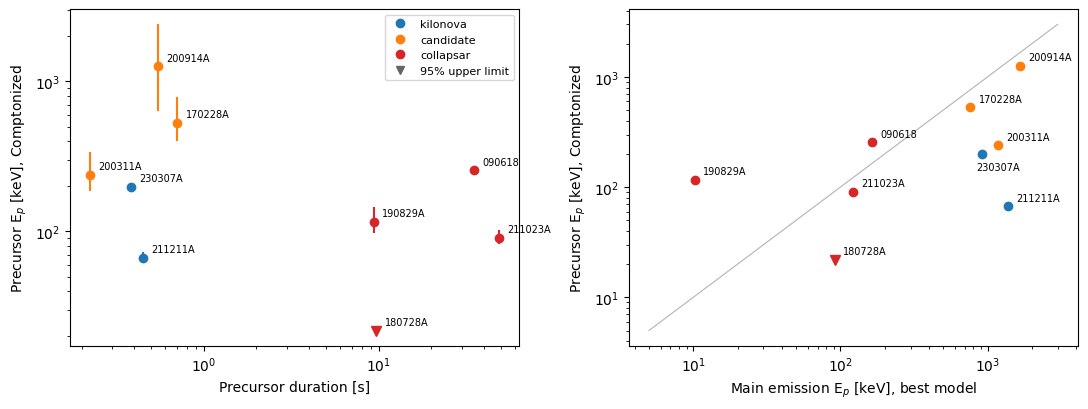

,group,T_pre,Ep_pre,Ep_main,Ep_main_best,usable,measured,lo,hi,limit,ratio,ratio_best,z,Ep_pre_rest
burst,,,,,,,,,,,,,,
GRB230307A,kilonova,0.384,198.673,917.636,914.041,True,True,3.800,3.800,NaN,0.217,0.217,0.065,211.587
GRB211211A,kilonova,0.448,66.748,1017.590,1379.730,True,True,5.386,6.494,NaN,0.066,0.048,0.076,71.821
GRB090618,collapsar,35.264,255.645,245.187,164.381,True,True,9.407,10.142,272.774,1.043,1.555,0.540,393.693
GRB170228A,candidate,0.704,531.642,762.258,762.258,True,True,131.178,252.082,1102.572,0.697,0.697,NaN,NaN
GRB180728A,collapsar,9.696,13.366,101.217,91.698,True,False,2.412,4.092,21.832,0.132,0.146,0.117,14.929
GRB190114C,collapsar,1.936,11.779,721.898,711.520,False,False,1.516,1.615,14.535,0.016,0.017,0.424,16.779
GRB190829A,collapsar,9.376,116.151,6.981,10.248,True,True,17.876,29.299,176.964,16.638,11.334,0.078,125.269
GRB200311A,candidate,0.224,239.131,1174.705,1174.705,True,True,53.579,100.128,462.497,0.204,0.204,NaN,NaN
GRB200914A,candidate,0.544,1260.179,1666.018,1666.018,True,True,629.359,1146.602,3495.572,0.756,0.756,NaN,NaN


In [8]:
known_230 = pd.read_csv(SHARED / "epeak_230307A.csv").set_index("label")
known_211 = pd.read_csv(SHARED / "epeak_211211A.csv").set_index("label")
rows = [dict(burst="GRB230307A", group="kilonova", T_pre=0.384, Ep_pre=known_230.Epeak_cpl_keV["pre"], Ep_main=known_230.Epeak_cpl_keV["m01"], Ep_main_best=known_230.Epeak_keV["m01"], usable=True, measured=True, lo=3.8, hi=3.8, limit=np.nan),
        dict(burst="GRB211211A", group="kilonova", T_pre=0.448, Ep_pre=known_211.Epeak_cpl_keV["pre"], Ep_main=known_211.Epeak_cpl_keV["f2_01_10"], Ep_main_best=known_211.Epeak_keV["f2_01_10"], usable=True, measured=True, lo=known_211.Epeak_err_lo["pre"], hi=known_211.Epeak_err_hi["pre"], limit=np.nan)]
for burst, g in fits_table.groupby("burst"):
    pre, main = g[g.episode == "pre"].iloc[0], g[g.episode == "main"].iloc[0]
    rows.append(dict(burst=burst, group=pre.group, T_pre=pre.t_stop - pre.t_start, Ep_pre=pre.Ep, Ep_main=main.Ep, Ep_main_best=main.Ep_band if main.dC_cpl_minus_band > 9.0 else main.Ep, usable=bool(pre.usable), measured=bool(pre.measured), lo=pre.Ep_err_lo, hi=pre.Ep_err_hi, limit=pre.Ep_limit_hi))
summary = pd.DataFrame(rows).set_index("burst")
summary["ratio"] = summary.Ep_pre / summary.Ep_main
summary["ratio_best"] = summary.Ep_pre / summary.Ep_main_best
summary["z"] = SAMPLE.z.reindex(summary.index)
summary.loc["GRB230307A", "z"], summary.loc["GRB211211A", "z"] = 0.065, 0.076
summary["Ep_pre_rest"] = summary.Ep_pre * (1 + summary.z)
summary.to_csv(SHARED / "sample_precursors.csv", float_format="%.5g")

def permutation_p(values, in_group, transform=np.log):
    '''Exact two-sided permutation test on the difference of the group means of transform(values).'''
    values, in_group = transform(np.asarray(values, float)), np.asarray(in_group, bool)
    observed = abs(values[in_group].mean() - values[~in_group].mean())
    n, hits, total = in_group.sum(), 0, 0
    for chosen in combinations(range(len(values)), int(n)):
        mask = np.zeros(len(values), bool)
        mask[list(chosen)] = True
        hits += abs(values[mask].mean() - values[~mask].mean()) >= observed - 1e-12
        total += 1
    return hits / total, total

use = summary[summary.measured]
is_merger = use.group != "collapsar"
print(f"Measured precursors only: {is_merger.sum()} mergers + candidates, {(~is_merger).sum()} collapsars")
for name, column in (("precursor E_p", "Ep_pre"), ("E_p ratio, Comptonized", "ratio"), ("E_p ratio, best model", "ratio_best"), ("precursor duration", "T_pre")):
    p, n = permutation_p(use[column], is_merger)
    print(f"  {name:24s} geometric means: mergers + candidates {np.exp(np.log(use[column][is_merger]).mean()):8.2f}, collapsars {np.exp(np.log(use[column][~is_merger]).mean()):8.2f}; p = {p:.3f} ({n} arrangements)")
for left_out in use.index:
    sub = use.drop(left_out)
    print(f"     without {left_out}: p(E_p) = {permutation_p(sub.Ep_pre, sub.group != 'collapsar')[0]:.3f}, p(ratio) = {permutation_p(sub.ratio, sub.group != 'collapsar')[0]:.3f}")

all_usable = summary[summary.usable].copy()
faint = ~all_usable.measured
all_usable.loc[faint, "Ep_pre"] = all_usable.limit[faint]
all_usable["ratio"] = all_usable.Ep_pre / all_usable.Ep_main
all_usable["ratio_best"] = all_usable.Ep_pre / all_usable.Ep_main_best
is_merger = all_usable.group != "collapsar"
print(f"\nAll usable precursors, by rank, unmeasured ones at their 95% limit ({', '.join(all_usable.index[faint])}): {is_merger.sum()} against {(~is_merger).sum()}")
for name, column in (("precursor E_p", "Ep_pre"), ("E_p ratio, Comptonized", "ratio"), ("E_p ratio, best model", "ratio_best")):
    p, n = permutation_p(all_usable[column], is_merger, rankdata)
    print(f"  {name:24s} p = {p:.3f} ({n} arrangements)")

spread = np.log10(use.Ep_pre[use.group != "collapsar"]).std(ddof=1)
print(f"\nScatter of log10 E_p among the mergers + candidates: {spread:.2f} dex")
for dex in (0.3, 0.5, 1.0):
    print(f"  to see a difference of {dex} dex (a factor {10**dex:.0f}) at p < 0.05 with 80% power: about {2 * (2.80 * spread / dex)**2:.0f} bursts in each group")

COLOURS = {"kilonova": "tab:blue", "candidate": "tab:orange", "collapsar": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for burst, row in summary.iterrows():
    colour = COLOURS[row.group]
    if not row.usable:
        continue
    if row.measured:
        yerr = None if np.isnan(row.lo) else [[row.lo], [row.hi if np.isfinite(row.hi) else 0.0]]
        axes[0].errorbar(row.T_pre, row.Ep_pre, yerr=yerr, fmt="o", color=colour, ms=6)
        axes[1].plot(row.Ep_main_best, row.Ep_pre, "o", color=colour, ms=6)
        y = row.Ep_pre
    else:
        axes[0].plot(row.T_pre, row.limit, "v", color=colour, ms=7)
        axes[1].plot(row.Ep_main_best, row.limit, "v", color=colour, ms=7)
        y = row.limit
    axes[0].annotate(burst[3:], (row.T_pre, y), textcoords="offset points", xytext=(6, 4), fontsize=7)
    below = burst == "GRB230307A"
    axes[1].annotate(burst[3:], (row.Ep_main_best, y), textcoords="offset points", xytext=(-4, -11) if below else (6, 4), fontsize=7)
axes[0].set(xscale="log", yscale="log", xlabel="Precursor duration [s]", ylabel="Precursor E$_p$ [keV], Comptonized")
axes[1].set(xscale="log", yscale="log", xlabel="Main emission E$_p$ [keV], best model", ylabel="Precursor E$_p$ [keV], Comptonized")
span = np.array([5.0, 3000.0])
axes[1].plot(span, span, color="0.7", lw=0.8)
for name, colour in COLOURS.items():
    axes[0].plot([], [], "o", color=colour, label=name)
axes[0].plot([], [], "v", color="0.4", label="95% upper limit")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "18_precursor_epeak_by_class.png", dpi=200)
plt.show()

rows = []
for burst, row in summary.iterrows():
    if burst in windows and windows[burst]:
        w = windows[burst]
        rows += [dict(burst=burst, label=f"{burst}_pre", t_start=w["pre_start"], t_stop=w["pre_stop"]), dict(burst=burst, label=f"{burst}_main", t_start=w["main_start"], t_stop=w["main_stop"])]
pd.DataFrame(rows).to_csv(SHARED / "windows_sample.csv", index=False, float_format="%.5g")
summary.round(3)

Precursor E_p on its own doesn't separate the two groups. For the measured ones the geometric means are 292 and 139 keV with p = 0.34, and by rank with 180728A at its limit p = 0.29. Leaving out any one burst, p stays between 0.17 and 0.62. If anything the difference goes the opposite way to the starting idea: the merger group isn't softer, and collapsars have soft precursors too.

The ratio to the main emission does better among the measured ones: 0.05-0.76 for mergers and candidates, against 0.75, 1.6 and 11 for the three collapsars (best model), with p = 0.05-0.07. But it depends on what's left out. With 180728A in at its limit (a ratio below 0.24, which looks like the merger group) p is 0.11-0.29, and I don't think the hint means much yet. It isn't fully independent either, since the candidates were picked with criteria that include the main emission's hardness.

Duration separates them completely, p = 0.018, the smallest value possible here. That's circular, because a short precursor is part of what made them candidates, so it says nothing new.

The size of the sample is the real limit. With a scatter of 0.48 dex, a factor of 10 would show with about 4 bursts in each group, a factor of 3 needs about 14 and a factor of 2 about 40. We have 5 and 4. So this can already say the mergers' precursors aren't softer by a factor of 10, and it can't say anything about a factor of 2 or 3.

## 8. The shattering-flare budget across the sample

The same budget as notebook 19: a tidal energy rate of up to about 1e50 erg/s for the fiducial values, 20% efficiency, 10-1000 keV with no k-correction. Where the redshift is known this gives the rate each precursor would need. The three candidates have no redshift, so instead I ask how far away each could be before it needs the fiducial rate, and before it needs what GRB 230307A's needs (18 times that). If a precursor is a shattering flare, this limits where the burst can be.

In [9]:
FIDUCIAL = 1e50                     # erg/s
EFFICIENCY = 0.2

def l_iso(flux, z):
    return 4 * np.pi * Planck18.luminosity_distance(z).to("cm").value**2 * flux

def z_for(flux, multiple):
    distance = np.sqrt(multiple * FIDUCIAL * EFFICIENCY / (4 * np.pi * flux)) * u.cm
    return float(z_at_value(Planck18.luminosity_distance, distance.to("Mpc"), zmin=1e-4, zmax=10.0))

rows = []
for _, pre in fits_table[(fits_table.episode == "pre") & fits_table.usable].iterrows():
    z = SAMPLE.z[pre.burst]
    luminosity = np.nan if np.isnan(z) else l_iso(pre.flux_cpl, z)
    rows.append(dict(burst=pre.burst, group=pre.group, flux_10_1000=pre.flux_cpl, z=z, L_iso=luminosity, rate_over_fiducial=luminosity / EFFICIENCY / FIDUCIAL,
                     z_at_fiducial=z_for(pre.flux_cpl, 1.0), z_at_18_times=z_for(pre.flux_cpl, 18.0)))
budget = pd.DataFrame(rows).set_index("burst")
budget.to_csv(SHARED / "sample_budget.csv", float_format="%.4g")
print(budget.to_string(float_format=lambda x: f"{x:.3g}"))

                group  flux_10_1000      z    L_iso  rate_over_fiducial  z_at_fiducial  z_at_18_times
burst                                                                                                
GRB170228A  candidate      1.06e-06    NaN      NaN                 NaN         0.0842          0.313
GRB200311A  candidate       1.4e-06    NaN      NaN                 NaN         0.0739          0.277
GRB200914A  candidate      9.77e-07    NaN      NaN                 NaN         0.0877          0.325
GRB180728A  collapsar      1.16e-07  0.117 4.41e+48               0.221          0.232           0.79
GRB190829A  collapsar      2.44e-07 0.0785 3.96e+48               0.198          0.167          0.583
GRB090618   collapsar      9.88e-07   0.54 1.21e+51                60.6         0.0872          0.323
GRB211023A  collapsar      7.14e-08   0.39 4.04e+49                2.02          0.288          0.964


The candidates' precursor fluxes are all about 1e-6 erg/cm2/s, the same as GRB 211211A's (1.2e-6). So they'd fit the fiducial budget only if closer than z of about 0.07-0.09, which is where the two kilonova bursts are (0.065 and 0.076), and they'd reach GRB 230307A's 18 times the fiducial value by z of about 0.28-0.33. So if these precursors are shattering flares at the fiducial values, these bursts should be nearby. None of the three has a measured redshift (Tan et al.), so that's a prediction a redshift could test. These limits are generous: there's no k-correction, and for a precursor this hard 10-1000 keV leaves out a lot of the energy.

The collapsars show the budget can't pick out mergers on its own. 180728A and 190829A would need only 0.2 times the fiducial rate and 211023A 2 times; only 090618 is far outside, at 61 times. It's a constraint on the model, not a classifier. The one thing that does set those collapsars apart from a flare is their length, about 10-50 s, against a flare lasting a fraction of a second, and that's again the duration.

## 9. What this says

- **The pipeline runs on new bursts with one rule and no tuning.** Windows agree with the published ones, and the fits agree with the catalogue and with Tan et al., except where this says otherwise (200914A, and 10-20% in the two longest bursts).
- **In this first sample, the precursor's E_p doesn't separate mergers from collapsars.** The candidates' precursors are hard, and some collapsars' are soft. So low E_peak on its own isn't a merger signature here. Either answer was going to be a result, and with 5 against 4 bursts this one only excludes a large difference.
- **The ratio to the main emission is the only hint,** and it doesn't survive including 180728A. It's worth testing on more bursts, but not worth claiming.
- **Candidates aren't confirmed mergers.** If low E_peak really were general for mergers, that would be an argument against these three being mergers, and I can't tell these two apart without a kilonova or a redshift.
- **None of these precursors has the signal for a trustworthy Haar MVT,** by my reading of the trust curve. Only bright ones like GRB 230307A's do, so with this method a joint diagnostic could only be used on a few bursts.
- **A redshift for a candidate would test the budget:** above z of about 0.3 it would need more than GRB 230307A's stretch.
- **What would make this stronger:** more collapsars with measured precursors, a sensitivity test so that 'too faint' has a stated meaning, and Zhu et al.'s full table.
- **The sample only has bursts with visible precursors,** so it tests what class such a burst is, not GRBs in general.